<a href="https://colab.research.google.com/github/SarveshKadam10/unet-shape-segmentation/blob/main/Unet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import random

In [2]:
IMG_SIZE = 128

def generate_sample(shape_type):
    # Random dark background
    bg_intensity = np.random.randint(0, 56)

    image = np.full(
        (IMG_SIZE, IMG_SIZE),
        bg_intensity,
        dtype=np.uint8
    )

    # Binary ground-truth mask
    mask = np.zeros(
        (IMG_SIZE, IMG_SIZE),
        dtype=np.uint8
    )

    # Random bright object
    object_intensity = np.random.randint(200, 256)

    if shape_type == "circle":

        radius = np.random.randint(10, 26)

        cx = np.random.randint(radius, IMG_SIZE - radius)
        cy = np.random.randint(radius, IMG_SIZE - radius)

        cv2.circle(
            image,
            (cx, cy),
            radius,
            int(object_intensity),
            -1
        )

        cv2.circle(
            mask,
            (cx, cy),
            radius,
            1,
            -1
        )

    elif shape_type == "square":

        half = np.random.randint(12, 26)

        cx = np.random.randint(half + 5, IMG_SIZE - half - 5)
        cy = np.random.randint(half + 5, IMG_SIZE - half - 5)

        angle = np.random.uniform(0, 360)

        rect = (
            (cx, cy),
            (2 * half, 2 * half),
            angle
        )

        points = cv2.boxPoints(rect).astype(np.int32)

        cv2.fillPoly(
            image,
            [points],
            int(object_intensity)
        )

        cv2.fillPoly(
            mask,
            [points],
            1
        )

    elif shape_type == "triangle":

        cx = np.random.randint(35, IMG_SIZE - 35)
        cy = np.random.randint(35, IMG_SIZE - 35)

        size = np.random.randint(15, 31)
        angle = np.random.uniform(0, 2 * np.pi)

        points = []

        for i in range(3):

            theta = angle + i * 2 * np.pi / 3

            x = int(cx + size * np.cos(theta))
            y = int(cy + size * np.sin(theta))

            points.append([x, y])

        points = np.array(points, dtype=np.int32)

        cv2.fillPoly(
            image,
            [points],
            int(object_intensity)
        )

        cv2.fillPoly(
            mask,
            [points],
            1
        )

    return image, mask

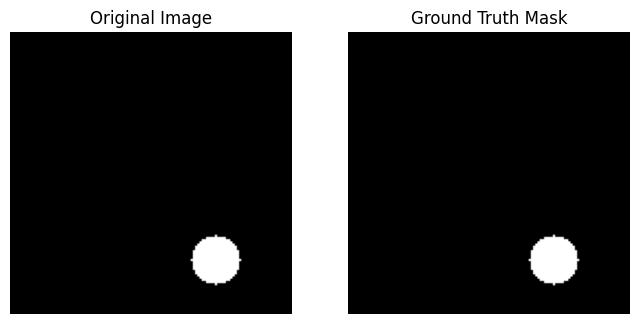

In [3]:
image, mask = generate_sample("circle")

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.show()

In [4]:
def generate_dataset(num_samples):
    images = []
    masks = []
    labels = []

    shapes = ["circle", "square", "triangle"]

    for i in range(num_samples):
        shape = shapes[i % 3]

        image, mask = generate_sample(shape)

        images.append(image)
        masks.append(mask)
        labels.append(shape)

    # Shuffle everything together
    indices = np.random.permutation(num_samples)

    images = np.array(images)[indices]
    masks = np.array(masks)[indices]
    labels = np.array(labels)[indices]

    return images, masks, labels


# Generate datasets
train_images, train_masks, train_labels = generate_dataset(1000)
test_images, test_masks, test_labels = generate_dataset(200)

print("Training images:", train_images.shape)
print("Training masks:", train_masks.shape)

print("Test images:", test_images.shape)
print("Test masks:", test_masks.shape)

Training images: (1000, 128, 128)
Training masks: (1000, 128, 128)
Test images: (200, 128, 128)
Test masks: (200, 128, 128)


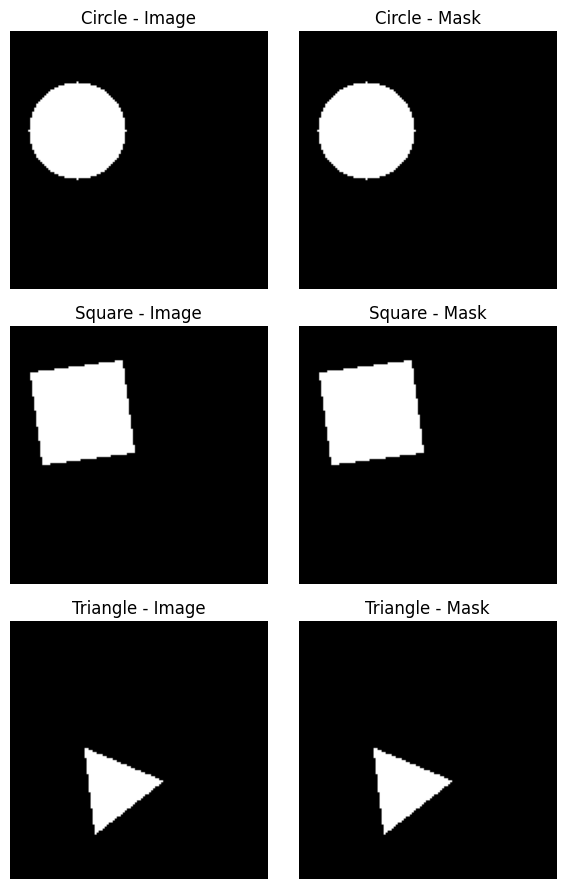

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(6, 9))

for row, shape in enumerate(["circle", "square", "triangle"]):

    idx = np.where(train_labels == shape)[0][0]

    axes[row, 0].imshow(train_images[idx], cmap="gray")
    axes[row, 0].set_title(f"{shape.capitalize()} - Image")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(train_masks[idx], cmap="gray")
    axes[row, 1].set_title(f"{shape.capitalize()} - Mask")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
# Normalize images from 0-255 to 0-1
train_images = train_images.astype(np.float32) / 255.0
test_images = test_images.astype(np.float32) / 255.0

# Convert masks to float
train_masks = train_masks.astype(np.float32)
test_masks = test_masks.astype(np.float32)

# Add channel dimension
train_images = np.expand_dims(train_images, axis=-1)
test_images = np.expand_dims(test_images, axis=-1)

train_masks = np.expand_dims(train_masks, axis=-1)
test_masks = np.expand_dims(test_masks, axis=-1)

print("Training images:", train_images.shape)
print("Training masks:", train_masks.shape)
print("Test images:", test_images.shape)
print("Test masks:", test_masks.shape)

print("Image range:", train_images.min(), "to", train_images.max())
print("Mask values:", np.unique(train_masks))

Training images: (1000, 128, 128, 1)
Training masks: (1000, 128, 128, 1)
Test images: (200, 128, 128, 1)
Test masks: (200, 128, 128, 1)
Image range: 0.0 to 1.0
Mask values: [0. 1.]


In [7]:
import tensorflow as tf
from tensorflow.keras import layers, Model

In [8]:
def build_unet():

    inputs = layers.Input((128, 128, 1))

    # Encoder / Downsampling

    # Block 1
    c1 = layers.Conv2D(16, 3, activation="relu", padding="same")(inputs)
    c1 = layers.Conv2D(16, 3, activation="relu", padding="same")(c1)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    # Block 2
    c2 = layers.Conv2D(32, 3, activation="relu", padding="same")(p1)
    c2 = layers.Conv2D(32, 3, activation="relu", padding="same")(c2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    # Bottleneck

    b = layers.Conv2D(64, 3, activation="relu", padding="same")(p2)
    b = layers.Conv2D(64, 3, activation="relu", padding="same")(b)

    # Decoder / Upsampling

    # Block 1
    u1 = layers.Conv2DTranspose(
        32, 2, strides=2, padding="same"
    )(b)

    u1 = layers.concatenate([u1, c2])

    c3 = layers.Conv2D(32, 3, activation="relu", padding="same")(u1)
    c3 = layers.Conv2D(32, 3, activation="relu", padding="same")(c3)

    # Block 2
    u2 = layers.Conv2DTranspose(
        16, 2, strides=2, padding="same"
    )(c3)

    u2 = layers.concatenate([u2, c1])

    c4 = layers.Conv2D(16, 3, activation="relu", padding="same")(u2)
    c4 = layers.Conv2D(16, 3, activation="relu", padding="same")(c4)

    # Binary segmentation output
    outputs = layers.Conv2D(
        1, 1, activation="sigmoid"
    )(c4)

    return Model(inputs, outputs)


model = build_unet()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 64, 64,    │      8,224 │ conv2d_5[0][0]    │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 64)               │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │     18,464 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d_6[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 128, 128,  │      2,064 │ conv2d_7[0][0]    │
│ (Conv2DTranspose)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 32)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 128, 128,  │      4,624 │ concatenate_1[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │      2,320 │ conv2d_8[0][0]  

 Total params: 116,753 (456.07 KB)

 Trainable params: 116,753 (456.07 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [11]:
history = model.fit(
    train_images,
    train_masks,
    batch_size=16,
    epochs=15,
    shuffle=True
)

Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 1.0000 - loss: 3.5954e-06
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 1.0000 - loss: 2.9230e-06
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 1.0000 - loss: 2.6183e-06
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 1.0000 - loss: 2.3011e-06
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 1.0000 - loss: 1.9664e-06
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 1.0000 - loss: 1.8501e-06
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 140s 2s/step - accuracy: 1.0000 - loss: 1.5482e-06
Epoch 8/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 152s 2s/step - accuracy: 1.0000 - loss: 1.4994e-06
Epoch 9/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 1.0000 - loss: 1.2720e-06
Epoch 10/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - accuracy: 1.0000 - loss: 1.1687e-06
Epoch 11/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 122s 2s/step - accuracy: 1.0000 - loss: 1.1062e-06
Epoch 12/15
63/63 ━

In [12]:
pred_probs = model.predict(test_images)

# Convert probabilities to binary predictions
pred_masks = (pred_probs >= 0.5).astype(np.uint8)

print("Prediction shape:", pred_masks.shape)
print("Unique predicted values:", np.unique(pred_masks))

7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step
Prediction shape: (200, 128, 128, 1)
Unique predicted values: [0 1]


In [13]:
y_true = test_masks.astype(np.uint8).flatten()
y_pred = pred_masks.flatten()

TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)

TP: 214160
TN: 3062640
FP: 0
FN: 0


In [17]:
# Flatten masks so every pixel can be compared
y_true = test_masks.astype(np.uint8).flatten()
y_pred = pred_masks.flatten()

TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

accuracy = (TP + TN) / (TP + TN + FP + FN)
iou = TP / (TP + FP + FN)

print("TP:", TP)
print("TN:", TN)
print("FP:", FP)
print("FN:", FN)

print(f"\nTest Accuracy: {accuracy:.6f}")
print(f"Test IoU: {iou:.6f}")

TP: 214160
TN: 3062640
FP: 0
FN: 0

Test Accuracy: 1.000000
Test IoU: 1.000000


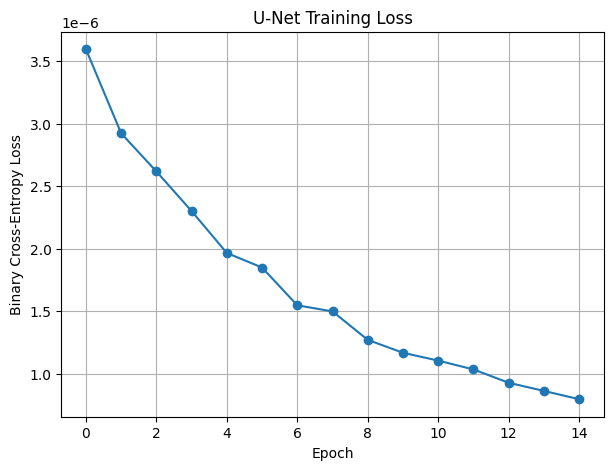

In [18]:
plt.figure(figsize=(7, 5))

plt.plot(history.history["loss"], marker="o")

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("U-Net Training Loss")
plt.grid(True)

plt.show()

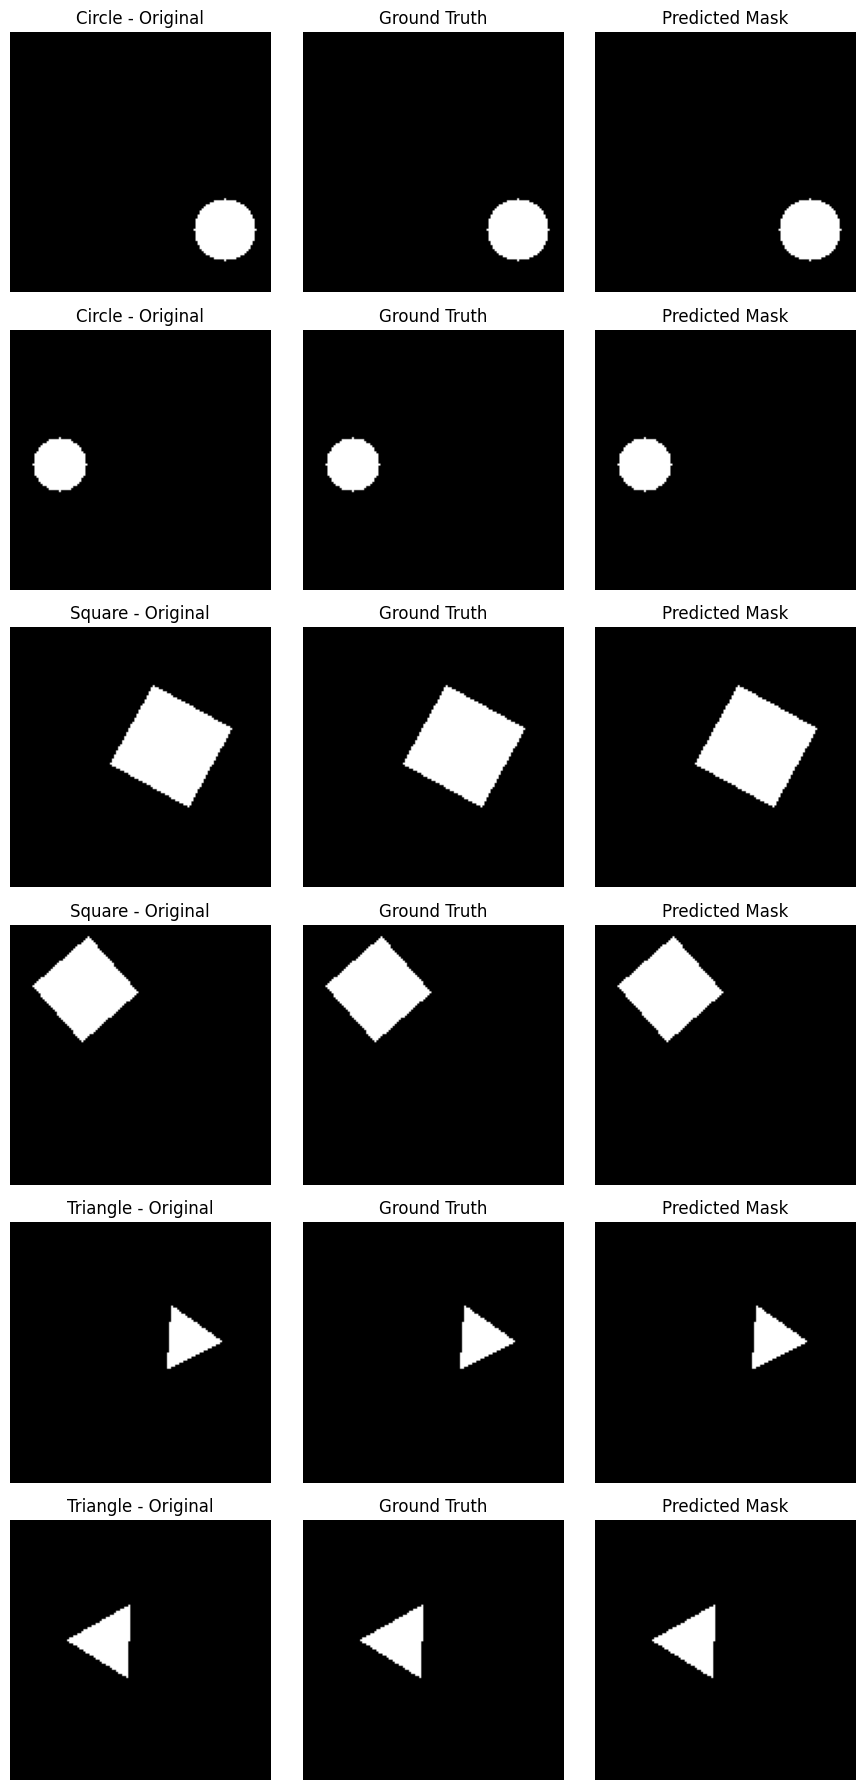

In [19]:
# Select 2 random test examples from each shape
selected_indices = []

for shape in ["circle", "square", "triangle"]:
    shape_indices = np.where(test_labels == shape)[0]
    chosen = np.random.choice(shape_indices, 2, replace=False)
    selected_indices.extend(chosen)

# Plot original, ground truth, and prediction
fig, axes = plt.subplots(6, 3, figsize=(9, 18))

for row, idx in enumerate(selected_indices):

    # Original image
    axes[row, 0].imshow(
        test_images[idx].squeeze(),
        cmap="gray"
    )
    axes[row, 0].set_title(
        f"{test_labels[idx].capitalize()} - Original"
    )

    # Ground-truth mask
    axes[row, 1].imshow(
        test_masks[idx].squeeze(),
        cmap="gray"
    )
    axes[row, 1].set_title("Ground Truth")

    # Predicted mask
    axes[row, 2].imshow(
        pred_masks[idx].squeeze(),
        cmap="gray"
    )
    axes[row, 2].set_title("Predicted Mask")

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

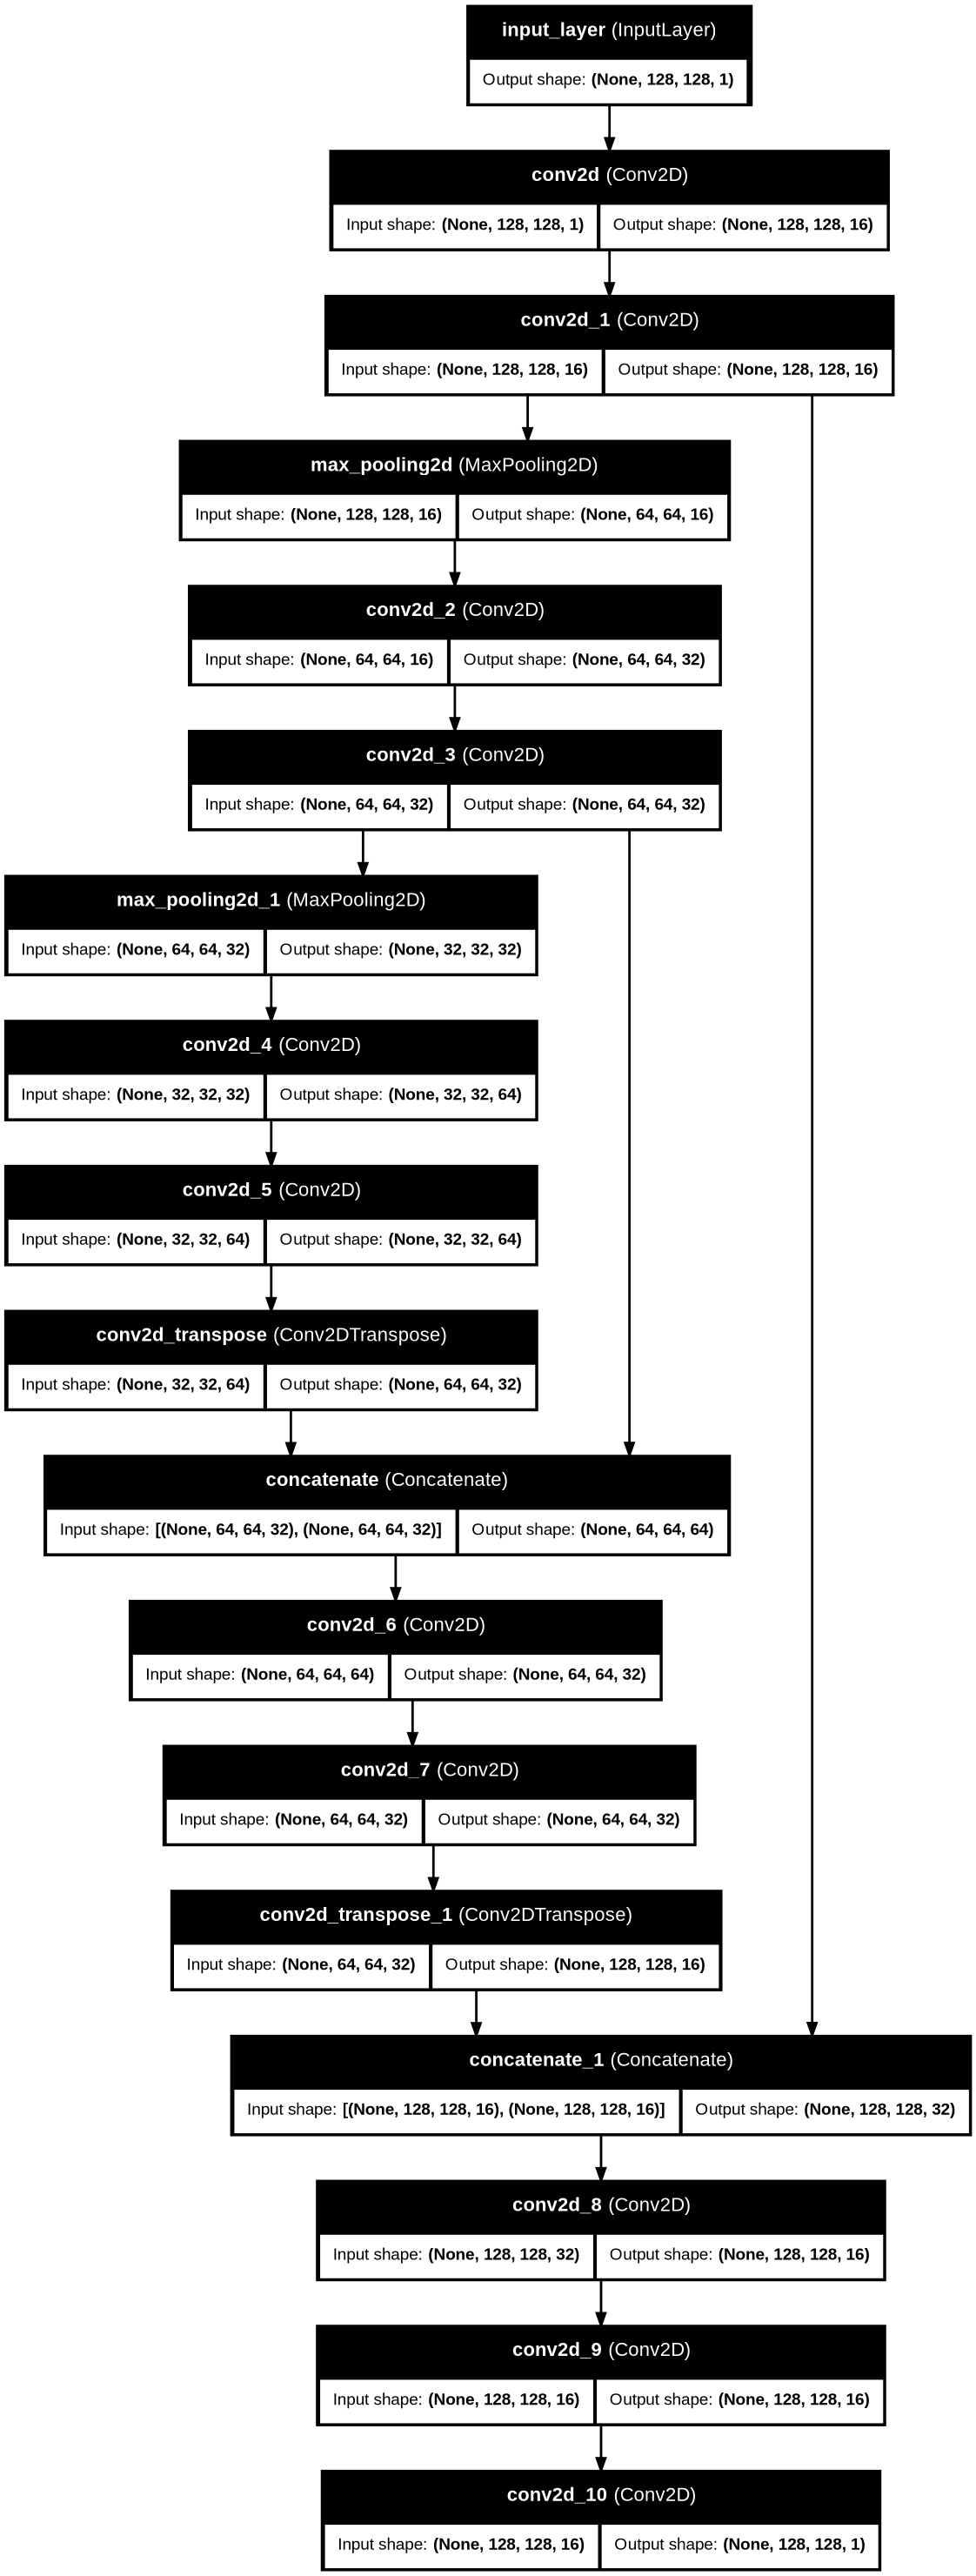

In [20]:
from tensorflow.keras.utils import plot_model

plot_model(
    model,
    to_file="unet_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    dpi=100
)

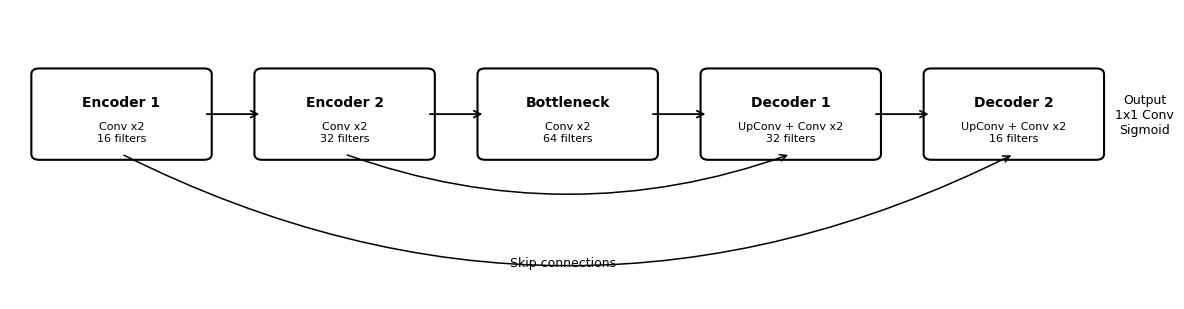

In [22]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.set_xlim(0, 12)
ax.set_ylim(0, 4)
ax.axis("off")

blocks = [
    (0.3, "Encoder 1", "Conv x2\n16 filters"),
    (2.6, "Encoder 2", "Conv x2\n32 filters"),
    (4.9, "Bottleneck", "Conv x2\n64 filters"),
    (7.2, "Decoder 1", "UpConv + Conv x2\n32 filters"),
    (9.5, "Decoder 2", "UpConv + Conv x2\n16 filters"),
]

box_w = 1.7
box_h = 1.1
y = 2.0

for x, title, details in blocks:
    box = FancyBboxPatch(
        (x, y),
        box_w,
        box_h,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        fill=False
    )
    ax.add_patch(box)

    ax.text(
        x + box_w/2,
        y + 0.72,
        title,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        x + box_w/2,
        y + 0.30,
        details,
        ha="center",
        va="center",
        fontsize=8
    )

for i in range(len(blocks) - 1):
    x1 = blocks[i][0] + box_w
    x2 = blocks[i+1][0]

    arrow = FancyArrowPatch(
        (x1, y + box_h/2),
        (x2, y + box_h/2),
        arrowstyle="->",
        mutation_scale=12,
        linewidth=1.3
    )
    ax.add_patch(arrow)

ax.text(
    11.7,
    y + box_h/2,
    "Output\n1x1 Conv\nSigmoid",
    ha="center",
    va="center",
    fontsize=9
)

# Skip connection: Encoder 1 -> Decoder 2
skip1 = FancyArrowPatch(
    (1.15, y),
    (10.35, y),
    connectionstyle="arc3,rad=0.25",
    arrowstyle="->",
    mutation_scale=12,
    linewidth=1.1
)
ax.add_patch(skip1)

# Skip connection: Encoder 2 -> Decoder 1
skip2 = FancyArrowPatch(
    (3.45, y),
    (8.05, y),
    connectionstyle="arc3,rad=0.18",
    arrowstyle="->",
    mutation_scale=12,
    linewidth=1.1
)
ax.add_patch(skip2)

ax.text(5.7, 0.45, "Skip connections", ha="center", fontsize=9)

plt.tight_layout()

plt.savefig(
    "compact_unet_architecture.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()